# 06 · Stage 6: the report charts (spec §9)

**Status:** chart gate held on 21 Oct 2026; its decisions are applied here and the charts re-rendered (§6). Headline titles follow Nithin's write-up.

The four charts below are the report's figures, each made twice (decision #9):
- a seaborn/matplotlib PNG in `reports/figures/`;
- a Plotly HTML in `reports/interactive/` for the webpage.

The production code is `src/gilt_study/report_charts.py` (`python -m gilt_study.report_charts`). This notebook shows the data behind each chart and the reasoning for each design choice.
- Every chart has a **caption** under it that explains each band, bar and marker.
- Exact p-values are in the **appendix table**: `reports/tables/appendix_p_values.csv` and `.html` (§5).

| # | Chart | Question it answers for the PM |
|---|---|---|
| 1 | `report_1_paths`: average path T-10…T+10, M2 and M3, with 95% bands | What does the auctioned gilt do around the auction, against what random days look like? |
| 2 | `report_2_by_bucket`: the three numbers by bucket (M2, M3) and the M1b level | Pre, day, post: which deviation from the index-neutral T close has paid, and in which bucket? |
| 3 | `report_3_by_regime`: the same by regime | Has the pattern changed from pre-crisis to QE to active QT? |
| 4 | `report_4_ex_ante_drivers`: ex-ante regression coefficients | Which things known before bidding predict a bigger number? |

**Inference shown in every chart.**
- Bars and bands are 95% CIs from standard errors clustered by auction week (± 1.96 SE).
- Marker fill carries the **lead p-value** (decision #20): filled if p < 0.05, hollow otherwise. The lead p is placebo-centred for the M2 and M3 means, and clustered for M1b and the regression coefficients, which have no placebo.
- A hollow marker can have a CI that excludes zero, e.g. M2 post-auction for all auctions: clustered p 0.006, placebo p 0.074. This is decision #20 at work, not a contradiction: the placebo test is stricter there.

**Colours** (dataviz method; validator run 21 Oct 2026):
- buckets: categorical slots 1–3, as in Stages 3–5;
- regimes: slots 7, 4, 5. Worst CVD ΔE is 16.3 and the normal-vision ΔE 19.6. Two slots fall below 3:1 contrast, so every series is also named in the legend, the hover and the tables;
- "all auctions": neutral ink;
- single-series charts: slot 1.

Text never takes a series colour, and every chart has one y-axis.

**Signs:** every number is in bp; **positive = the gilt cheapened**.

In [1]:
import warnings

import numpy as np
import pandas as pd

from gilt_study import analysis as an, placebo as pl, plotting, report_charts as rc

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 200)
plotting.set_seaborn_theme()
pfmt = lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"

## 1. The average path around the auction

**Data**
- **M2 (B-β)**: the CAR of all 912 auctions.
- **M3**: the residual change relative to T-6. Only the 367 auctions with a residual on **every** day T-10…T+10 are used, so the line is one fixed set of auctions. With a changing set, a kink could be a change of sample.
  - The three numbers in chart 2 use each window's full sample (M3 pre 395, day 417, post 416), so chart 1 at T-1 is close to, but not exactly, chart 2's pre number.

**Bands**
- **Blue:** the 95% CI of the mean at each k, with SEs clustered by auction week. The CI is zero at T-6 by construction.
- **Grey, dashed edges:** the placebo 95% range. These are the 2.5–97.5 percentiles of 1,000 placebo mean paths: the same gilts on random non-auction dates in the same bucket (decision #18).
  - Where the blue line leaves the grey range, ordinary days do not produce that path.
  - The M2 placebo range drifts down after T-6. AR has no intercept, so the β-adjusted change has a small negative drift on ordinary days. The p-values are centred on that drift (decision #20).

**Window markers:** dotted lines at T-6, T-1, T and T+5 mark the PM's three numbers.

The caption under the chart explains both bands (chart gate: keep both).

**T-10 → T-1 and the M3 total move** (added after seeing this chart, chart gate 21 Oct 2026)
- M3 starts to rise around T-8, before the main pre-auction window opens at T-6. So the appendix and notebook 05 also report:
  - **T-10 → T-1**, as a robustness pre-auction window for M2 and M3;
  - **the M3 total move T-10 → T+1**.
- Both are computed on their own samples with the same placebo (own random stream, so no earlier number changes). They are not drawn.

In [2]:
H = pd.read_csv(an.OUT_DIR / "headline.csv")
x = H[H.measure.isin(["pre10", "total"]) & H.by.isin(["all", "bucket"])].copy()
x["p_placebo"] = x["p_placebo"].map(pfmt)
x[["set", "group", "measure", "n", "mean_bp", "p_placebo", "n_placebo", "p_cluster"]].round(3)

,set,group,measure,n,mean_bp,p_placebo,n_placebo,p_cluster
3,"M2 (B-β), all years",all,pre10,912.0,0.275,0.215,897.0,0.231
13,"M2 (B-β), all years",short,pre10,324.0,0.190,0.871,321.0,0.749
14,"M2 (B-β), all years",medium,pre10,289.0,0.009,0.738,277.0,0.969
15,"M2 (B-β), all years",long,pre10,299.0,0.625,0.006,299.0,0.031
35,"M3, 1999-2017",all,pre10,367.0,0.604,< 0.001,364.0,0.000
36,"M3, 1999-2017",all,total,367.0,0.163,0.012,364.0,0.145
46,"M3, 1999-2017",short,pre10,117.0,1.032,< 0.001,117.0,0.000
47,"M3, 1999-2017",short,total,117.0,0.265,0.053,117.0,0.273
48,"M3, 1999-2017",medium,pre10,110.0,0.509,< 0.001,107.0,0.001
49,"M3, 1999-2017",medium,total,110.0,0.132,0.203,107.0,0.436


In [3]:
P1 = rc.path_data()
P1[P1.k.isin([-10, -6, -1, 0, 5, 10])].round(3)

,measure,k,n,placebo_lo,placebo_hi,placebo_mean,placebo_n,mean,se,lo,hi
0,M2 (B-β),-10,912,-0.282,0.303,-0.001,897,0.156,0.152,-0.141,0.453
4,M2 (B-β),-6,912,0.000,0.000,0.000,897,0.000,0.000,0.000,0.000
9,M2 (B-β),-1,912,-0.443,0.274,-0.065,897,0.431,0.172,0.095,0.768
10,M2 (B-β),0,912,-0.526,0.282,-0.109,897,0.469,0.192,0.092,0.845
15,M2 (B-β),5,912,-0.777,0.266,-0.221,897,0.036,0.225,-0.406,0.478
20,M2 (B-β),10,912,-0.918,0.282,-0.308,897,-0.013,0.283,-0.568,0.541
21,M3,-10,367,-0.085,0.100,0.010,364,-0.270,0.064,-0.396,-0.144
25,M3,-6,367,0.000,0.000,0.000,364,0.000,0.000,0.000,0.000
30,M3,-1,367,-0.115,0.096,-0.012,364,0.333,0.098,0.142,0.525
31,M3,0,367,-0.131,0.107,-0.016,364,-0.012,0.104,-0.216,0.192


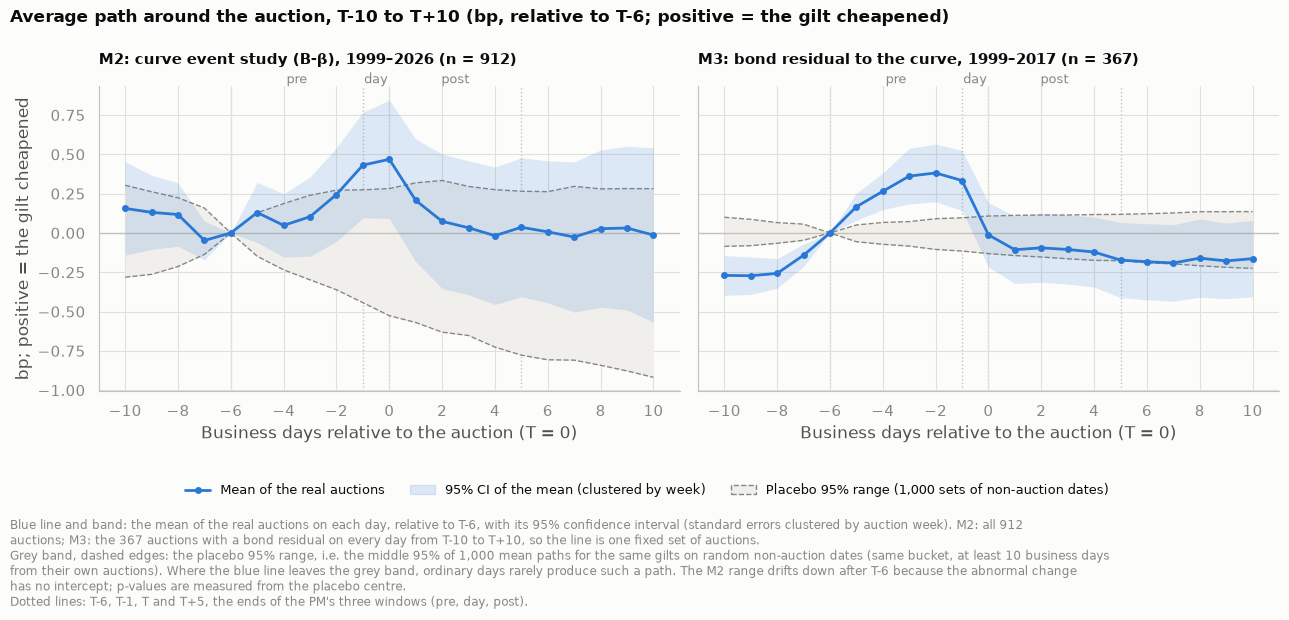

In [4]:
fig_s, fig_p = rc.chart_paths(P1)
plotting.save_pair("report_1_paths", fig_s, fig_p)
fig_p.show()

## 2. The three numbers by bucket, and the M1b level

**Panels and samples**
- The M2 and M3 panels hold the PM's three numbers; the M1b panel holds the at-auction **level** (1999–2017, baseline-adjusted).
- Each mean uses the full sample for that window. The placebo test drops auctions with no eligible date and reports how many it kept (`n placebo`).

**Design choices**
- **"All auctions"** is shown first, in neutral ink, so the headline sits next to the buckets without taking a categorical colour.
- **M1b, not M1:** post-2017 M1 levels are not concession estimates (decision #17), and to 2017 M1b removes each gilt's own rich/cheapness.

In [5]:
B = rc.bucket_data()
t = B[["panel", "group", "window", "n", "mean_bp", "lo", "hi", "lead_p", "lead_p_source", "n_placebo", "p_cluster"]].copy()
t["lead_p"] = t["lead_p"].map(pfmt)
t.round(3)

,panel,group,window,n,mean_bp,lo,hi,lead_p,lead_p_source,n_placebo,p_cluster
0,M2 (B-β),all auctions,pre,912.0,0.431,0.095,0.768,0.008,placebo-centred,897.0,0.012
1,M2 (B-β),all auctions,day,912.0,0.037,-0.116,0.190,0.345,placebo-centred,897.0,0.634
2,M2 (B-β),all auctions,post,912.0,-0.432,-0.737,-0.128,0.074,placebo-centred,897.0,0.006
3,M2 (B-β),short,pre,324.0,0.449,-0.417,1.314,0.249,placebo-centred,321.0,0.310
4,M2 (B-β),short,day,324.0,0.146,-0.233,0.525,0.250,placebo-centred,321.0,0.451
5,M2 (B-β),short,post,324.0,-0.678,-1.403,0.047,0.198,placebo-centred,321.0,0.068
6,M2 (B-β),medium,pre,289.0,0.358,-0.046,0.761,0.053,placebo-centred,277.0,0.084
7,M2 (B-β),medium,day,289.0,0.031,-0.162,0.224,0.359,placebo-centred,277.0,0.753
8,M2 (B-β),medium,post,289.0,-0.310,-0.701,0.081,0.494,placebo-centred,277.0,0.122
9,M2 (B-β),long,pre,299.0,0.484,0.044,0.924,0.004,placebo-centred,299.0,0.032


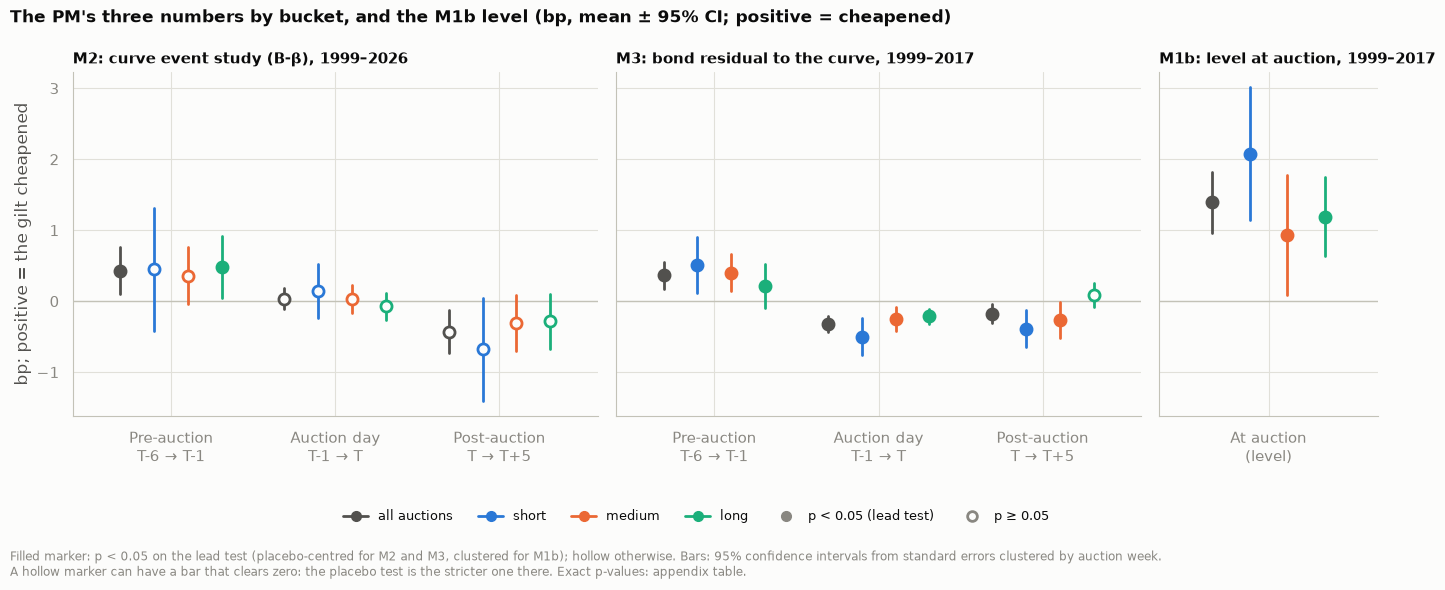

In [6]:
fig_s, fig_p = rc.chart_buckets(B)
plotting.save_pair("report_2_by_bucket", fig_s, fig_p)
fig_p.show()

## 3. By regime

**What is shown**
- Pre-crisis (Nov 1998 – 2008), QE (2009 – 22 Sep 2022, including the Feb–Oct 2022 passive QT, decision #14) and active QT (Nov 2022 – 16 Sep 2026).
- M3 and M1b end in Jul 2017, so they have no active-QT point.

**What is left out**
- The **LDI-stress window** (3 auctions, 2 weeks) is in the table below, but not the chart: it is reported, not interpreted (decision #20).
- The 2 post-QT-decision auctions are descriptive only.

**Placebo design** (chart gate: decision #18 stays the main placebo)
- Under decision #18, the placebo date of a QE-era auction can fall in any regime. The marker fill uses that design.
- The own-regime placebo (column `p_placebo_same_regime`) is a **labelled robustness check, added after seeing the results**, and is reported on every row of the appendix.
  - No marker in this chart changes fill under it; the caption says so, computed from the data.
  - Some p-values move a lot, e.g. M2 all-auction post: 0.074 → 0.014.

In [7]:
G = rc.regime_data()
H = pd.read_csv(an.OUT_DIR / "headline.csv")
t = H[(H.by == "regime")][["set", "group", "measure", "n", "mean_bp", "p_cluster", "p_placebo", "p_placebo_same_regime", "note"]].copy()
for c in ["p_cluster", "p_placebo", "p_placebo_same_regime"]:
    t[c] = t[c].map(lambda p: "" if pd.isna(p) else pfmt(p))
t.fillna("").round(3)

,set,group,measure,n,mean_bp,p_cluster,p_placebo,p_placebo_same_regime,note
16,"M2 (B-β), all years",pre-crisis,pre,129.0,1.129,0.034,0.003,0.002,
17,"M2 (B-β), all years",pre-crisis,day,129.0,-0.049,0.849,0.970,0.451,
18,"M2 (B-β), all years",pre-crisis,post,129.0,-0.878,0.035,0.262,0.135,
19,"M2 (B-β), all years",QE,pre,570.0,0.585,0.004,0.013,0.002,
20,"M2 (B-β), all years",QE,day,570.0,-0.040,0.636,0.910,0.666,
21,"M2 (B-β), all years",QE,post,570.0,-0.618,0.001,0.016,0.004,
22,"M2 (B-β), all years",LDI stress,pre,3.0,-18.262,0.387,< 0.001,,"reported, not interpreted (3 auctions in 2 weeks)"
23,"M2 (B-β), all years",LDI stress,day,3.0,0.120,0.992,0.848,,"reported, not interpreted (3 auctions in 2 weeks)"
24,"M2 (B-β), all years",LDI stress,post,3.0,4.996,0.631,0.107,,"reported, not interpreted (3 auctions in 2 weeks)"
25,"M2 (B-β), all years",active QT,pre,208.0,-0.162,0.620,0.645,0.688,


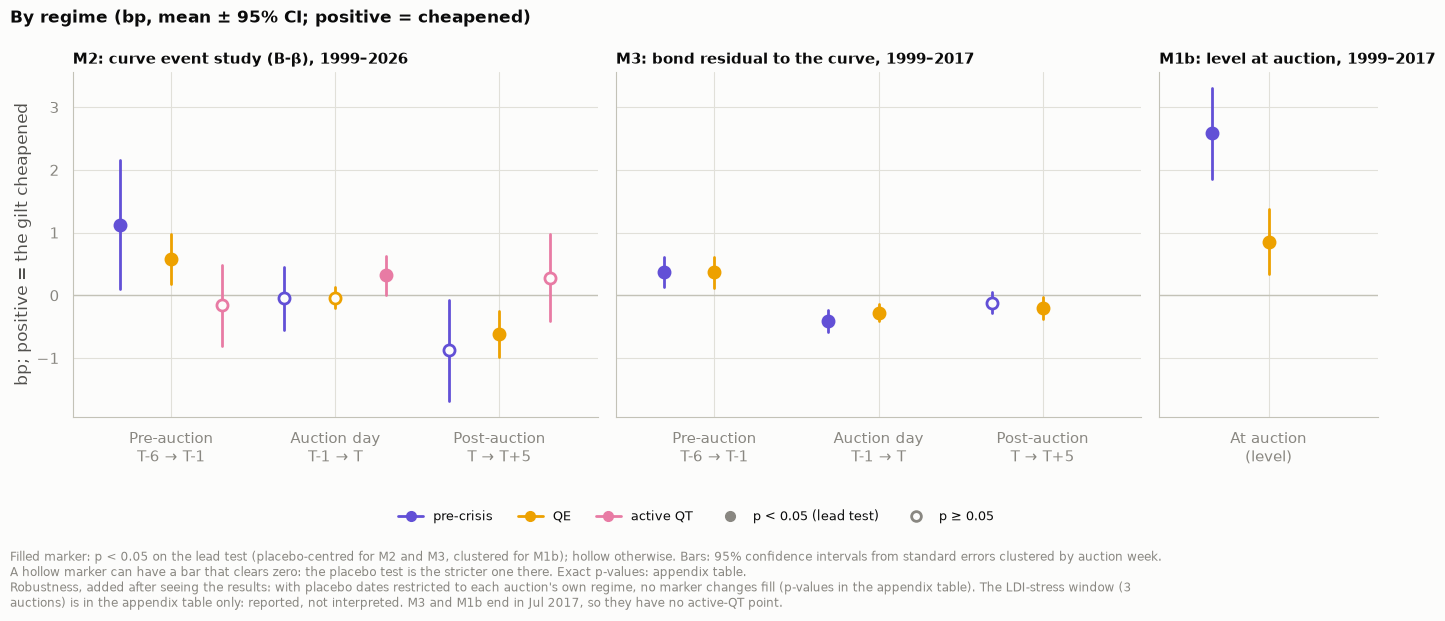

In [8]:
fig_s, fig_p = rc.chart_regimes(G)
plotting.save_pair("report_3_by_regime", fig_s, fig_p)
fig_p.show()

## 4. What predicts the numbers: ex-ante regressions

**Specification:** ex-ante only (decision #19), meaning variables known before bidding. These are the regressions the PM could use to predict.

**Layout**
- One panel per dependent variable: rows are M2 and M3, columns are pre, day and post.
- The last row holds the at-auction levels: M1b (1999–2017) and M1 with gilt fixed effects (2018–2026, identified within gilt).

**Design choices** (⚑ for review)
- **Raw units, not standardised.** DV01 is per £1m/bp and volatility per 1bp/day of 20-day realised volatility; every other variable is a 0/1 dummy. So the chart reads exactly like the tables and the PM can scale it: "an extra £1m/bp of DV01 adds x bp".
- **DV01 is priced at the T-1 model yield** (chart gate), so it is known before bidding. Notebook 05 §5 compares it with the old AAY-based DV01.
- **Regime dummies and the constant are left off the chart.** Regimes are chart 3, and the LDI dummy is not interpreted. Both are in the tables (notebook 05 §5).
- **Shared x-axis across the M2 and M3 rows,** so the windows compare directly. The level row has its own scale, because levels are larger.
- **Empty rows mean the term is not in that regression:**
  - QT sales start in 2022, so M3 and M1b (to 2017) have no QT term;
  - M1b excludes new issues by rule, so it has no new-issue term.

In [9]:
C = rc.coef_data()
C.pivot_table(index="label", columns="spec", values="coef", sort=False).reindex(list(rc.COEF_VARS.values())).round(2)

spec,M1b (1999-2017),"M1, gilt FE (2018-2026)",M2 pre (B-β),M2 day (B-β),M2 post (B-β),M3 pre,M3 day,M3 post
label,,,,,,,,
Auction DV01 (per £1m/bp),0.74,1.46,-0.07,-0.02,-0.26,0.21,0.06,0.12
Volatility to T-1 (per 1bp/day),0.46,0.14,0.18,0.06,-0.19,0.42,-0.17,0.02
Medium bucket (vs short),-1.77,-0.96,0.01,-0.08,0.72,-0.38,0.20,0.01
Long bucket (vs short),-2.29,-3.98,0.13,-0.14,1.13,-0.50,0.07,0.21
New issue (launch),NaN,0.50,1.06,0.16,0.61,0.44,0.22,-0.11
Syndication within ±5 days,-0.86,-0.53,0.30,0.09,-0.42,-0.27,-0.06,0.08
Tender within ±5 days,0.44,-0.98,-0.62,-0.30,-0.63,0.13,0.11,-0.11
BoE QT sale within ±5 days,NaN,-2.27,0.24,-0.07,0.23,NaN,NaN,NaN
BoE QE purchase within ±5 days,-0.20,-0.84,0.12,-0.11,-0.15,0.07,-0.03,-0.08


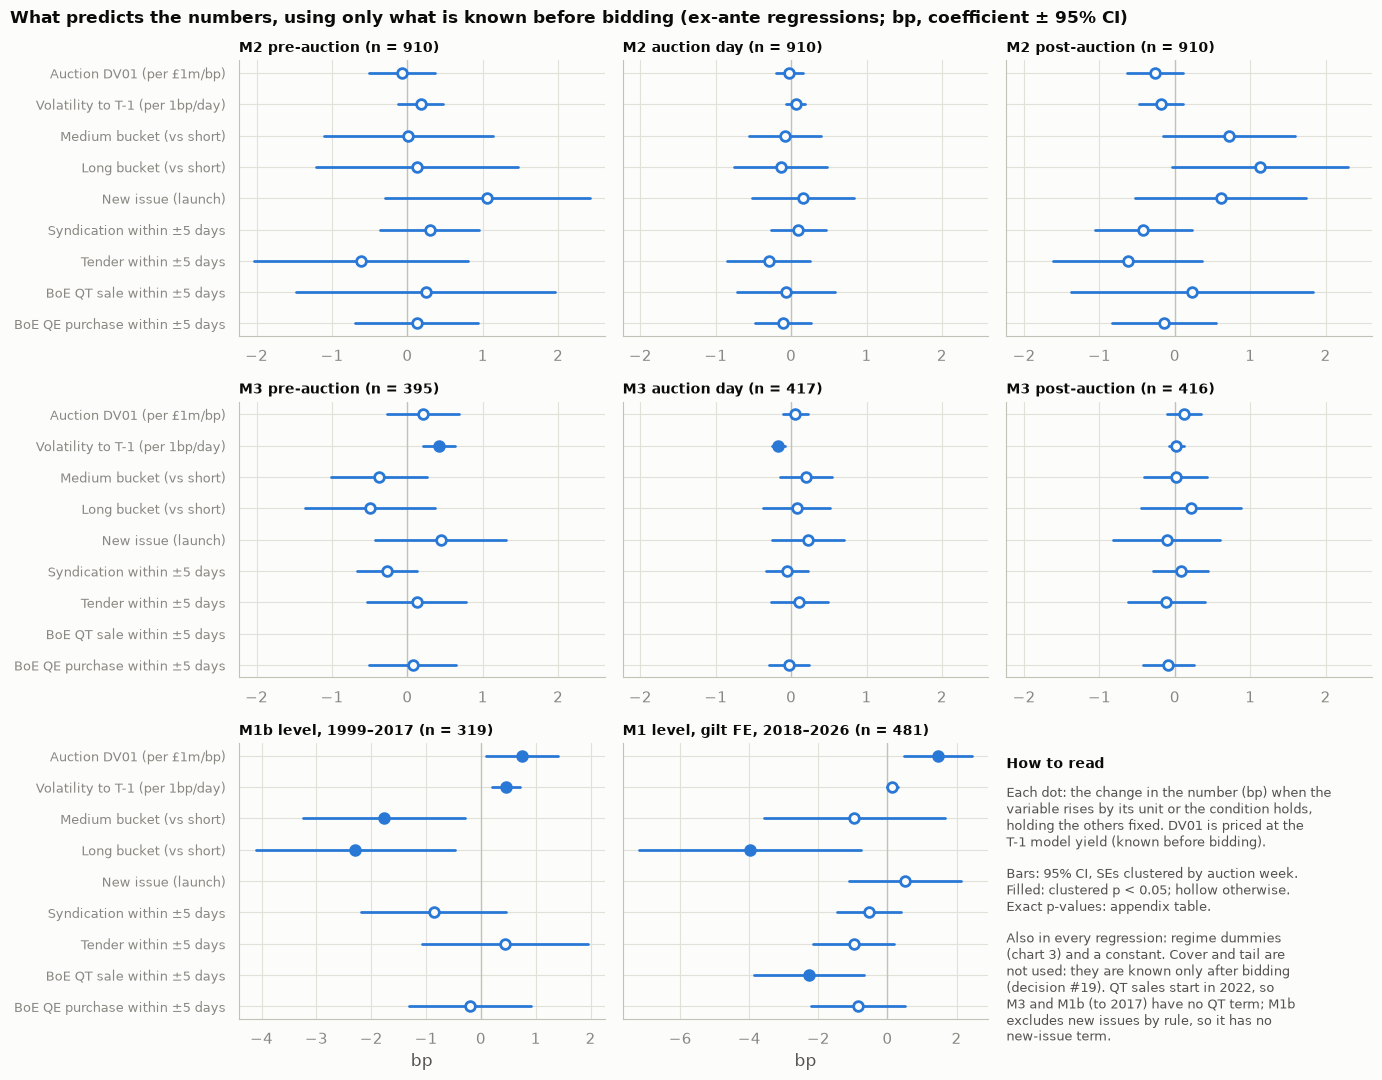

In [10]:
fig_s, fig_p = rc.chart_coefficients(C)
plotting.save_pair("report_4_ex_ante_drivers", fig_s, fig_p)
fig_p.show()

## 5. Appendix: exact p-values

Every point in charts 2–4, with:
- its estimate and 95% CI;
- the lead p and which test it is;
- the decision #18 placebo p and the own-regime robustness p;
- the clustered and Newey-West p.

The rows the charts leave out are included too: the LDI window, M1 on the M1b sample, the regime dummies, and the T-10 → T-1 and M3 total windows. The page is light and dark aware, for the report site.

In [11]:
csv, html = rc.write_appendix()
T = pd.read_csv(csv)
print(csv, html, len(T), "rows;", T.chart.value_counts().to_dict())
T.head(12).round(3)

/home/claude/gilt-auction-concession/reports/tables/appendix_p_values.csv /home/claude/gilt-auction-concession/reports/tables/appendix_p_values.html 156 rows; {'4': 67, 'table only': 44, '2': 28, '3': 17}


,section,chart,measure,group,window,n,estimate_bp,ci_low,ci_high,lead_p,lead_test,p_placebo,n_placebo,p_placebo_same_regime,p_clustered,p_newey_west,note
0,Means,2,"M2 (B-β), 1999–2026",all auctions,pre-auction T-6 → T-1,912,0.431,0.095,0.768,0.008,placebo-centred,0.008,897.0,0.001,0.012,0.006,NaN
1,Means,2,"M2 (B-β), 1999–2026",all auctions,auction day T-1 → T,912,0.037,-0.116,0.190,0.345,placebo-centred,0.345,897.0,0.199,0.634,0.627,NaN
2,Means,2,"M2 (B-β), 1999–2026",all auctions,post-auction T → T+5,912,-0.432,-0.737,-0.128,0.074,placebo-centred,0.074,897.0,0.014,0.006,0.003,NaN
3,Means,2,"M2 (B-β), 1999–2026",short,pre-auction T-6 → T-1,324,0.449,-0.417,1.314,0.249,placebo-centred,0.249,321.0,0.078,0.310,0.276,NaN
4,Means,2,"M2 (B-β), 1999–2026",short,auction day T-1 → T,324,0.146,-0.233,0.525,0.250,placebo-centred,0.250,321.0,0.085,0.451,0.462,NaN
5,Means,2,"M2 (B-β), 1999–2026",short,post-auction T → T+5,324,-0.678,-1.403,0.047,0.198,placebo-centred,0.198,321.0,0.040,0.068,0.060,NaN
6,Means,2,"M2 (B-β), 1999–2026",medium,pre-auction T-6 → T-1,289,0.358,-0.046,0.761,0.053,placebo-centred,0.053,277.0,0.070,0.084,0.088,NaN
7,Means,2,"M2 (B-β), 1999–2026",medium,auction day T-1 → T,289,0.031,-0.162,0.224,0.359,placebo-centred,0.359,277.0,0.316,0.753,0.721,NaN
8,Means,2,"M2 (B-β), 1999–2026",medium,post-auction T → T+5,289,-0.310,-0.701,0.081,0.494,placebo-centred,0.494,277.0,0.601,0.122,0.113,NaN
9,Means,2,"M2 (B-β), 1999–2026",long,pre-auction T-6 → T-1,299,0.484,0.044,0.924,0.004,placebo-centred,0.004,299.0,0.001,0.032,0.022,NaN


## 6. The chart gate (21 Oct 2026): decisions and what changed

| # | Question | Decision | Change |
|---|---|---|---|
| 1 | Chart 1 bands | Keep both | Captions explain each band |
| 2 | Chart 1 M3 sample | Fixed 367 auctions ✓ | none |
| 3 | Marker fill for the lead p | ✓, plus an appendix of exact p-values | `appendix_p_values.csv/.html` |
| 4 | Placebo for the regime rows | Decision #18 stays main; own-regime placebo is a labelled robustness check, added after seeing results | Robustness column on every appendix row; caption on chart 3 |
| 5 | Chart 4 layout | ✓ | none |
| 6 | Ex-ante DV01 | Priced at the T-1 model yield | Regressions re-run (notebook 05 §5) |
| 7 | Titles | Headline titles follow the write-up | none |
| new | Pre-auction window | T-10 → T-1 as robustness (M2, M3); report the M3 total move T-10 → T+1 | Measures, placebo, headline, appendix (§1) |

Stopping here.